# De los residuos a las varianzas de las tasas · LAB004–009

Estos gráficos reutilizan las salidas del notebook exploratorio de calibración. La calibración ajustó ocho coeficientes de la formulación G/F de 15 parámetros físicos. Para la covarianza condicionada a un rendimiento de etanol por fructosa fijo, se usaron siete columnas del Jacobiano. De esa covarianza se extraen tres varianzas para la diagonal del ensayo EKF.

La calibración guardada se ejecutó con Python global. Este notebook lee sus resultados y verifica la reconstrucción de las varianzas en el entorno `fermentation`.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy

prefix = Path(os.environ["CONDA_PREFIX"])
assert prefix.name.lower() == "fermentation" and Path(sys.prefix).resolve() == prefix.resolve()
print(f"Entorno para los gráficos {prefix.name} · SciPy {scipy.__version__}")
relative_source = Path("notebooks/diagnostics/zenteno_lab004_009_incertidumbre_exploratoria.ipynb")
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / relative_source).is_file())
source = json.loads((root / relative_source).read_text(encoding="utf-8"))
saved = json.loads("".join(source["cells"][-1]["outputs"][-1]["text"]))

names = saved["orden_columnas_jacobiano_log"]
kept = saved["orden_covarianza_Yef_fijo"]
rates = saved["orden_D_theta"]
theta = saved["coeficientes_reproducidos"]
residuals = pd.DataFrame(saved["filas"]).assign(residuo=saved["residuos_ponderados"])
J = np.asarray(saved["jacobiano_residuos_log"])
assert J.shape == (len(residuals), len(names))

labels = dict(mu0=r"$\mu_0$", betaG0=r"$\beta_{G0}$", betaF0=r"$\beta_{F0}$",
              Kig0=r"$K_{ig0}$", Kie0=r"$K_{ie0}$", Yxn=r"$Y_{X/N}$",
              Yeg=r"$Y_{E/G}$", Yef=r"$Y_{E/F}$")


Entorno para los gráficos fermentation · SciPy 1.13.1


## Residuos ponderados

Cada punto es la diferencia entre lo predicho y lo medido a una hora, dividida por la escala de error asignada. Un punto en +1 significa que el modelo predijo una escala de error por encima de la observación. La magnitud conjunta de esos residuos entra en la estimación de las varianzas.

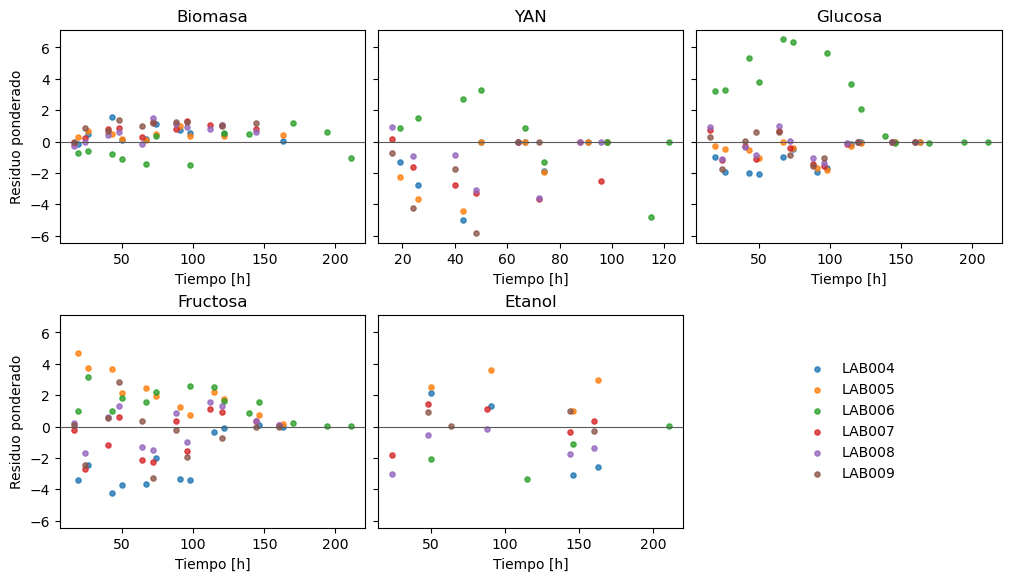

In [2]:
variables = {"X": "Biomasa", "N": "YAN", "G": "Glucosa", "F": "Fructosa", "E": "Etanol"}
fig, axes = plt.subplots(2, 3, figsize=(10, 5.7), sharey=True, layout="constrained")
labs = sorted(residuals.lote.unique())
for ax, (state, label) in zip(axes.flat, variables.items()):
    subset = residuals[residuals.variable == state]
    for index, lab in enumerate(labs):
        points = subset[subset.lote == lab]
        ax.scatter(points.t_h, points.residuo, s=14, alpha=.8, color=f"C{index}", label=lab)
    ax.axhline(0, color="0.35", linewidth=.8)
    ax.set(title=label, xlabel="Tiempo [h]")
axes[0, 0].set_ylabel("Residuo ponderado")
axes[1, 0].set_ylabel("Residuo ponderado")
legend_ax = axes[1, 2]
legend_ax.axis("off")
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
legend_ax.legend(handles, legend_labels, loc="center", frameon=False)
plt.show()


## Cuándo pueden compensarse dos coeficientes

Cada columna del Jacobiano muestra cómo responde el conjunto de residuos a un pequeño cambio en un coeficiente. El coseno entre columnas compara la dirección de esas respuestas. Cerca de +1, dos aumentos producen efectos parecidos y un aumento puede compensarse con una disminución del otro coeficiente. Cerca de −1, los efectos tienen signos opuestos. Esta similitud describe el Jacobiano, no la correlación entre coeficientes.

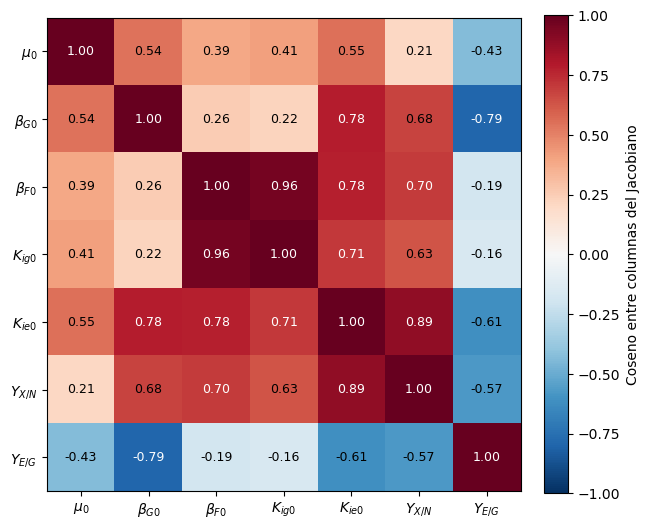

In [3]:
J_kept = J[:, [names.index(name) for name in kept]]
norms = np.linalg.norm(J_kept, axis=0)
assert (norms > 0).all()
normalized = J_kept / norms
similarity = normalized.T @ normalized
fig, ax = plt.subplots(figsize=(6.3, 5.2), layout="constrained")
im = ax.imshow(similarity, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(kept)), [labels[name] for name in kept])
ax.set_yticks(range(len(kept)), [labels[name] for name in kept])
for (i, j), value in np.ndenumerate(similarity):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center",
            color="white" if abs(value) > .68 else "black", fontsize=9)
fig.colorbar(im, ax=ax, label="Coseno entre columnas del Jacobiano")
plt.show()


## Del Jacobiano a la diagonal

En escala logarítmica, la aproximación local calcula la covarianza como $\hat{s}^2(J^\top J)^{-1}$, donde $\hat{s}^2$ es la suma de cuadrados de los residuos ponderados dividida por los grados de libertad. El código usa la descomposición en valores singulares para calcular esa expresión y convierte a unidades físicas. El gráfico compara la incertidumbre relativa con los ocho coeficientes incluidos y condicionando a $Y_{E/F}$ fijo. Para el EKF se usan las tres varianzas en unidades físicas. Los porcentajes sirven para comparar las tasas entre sí.

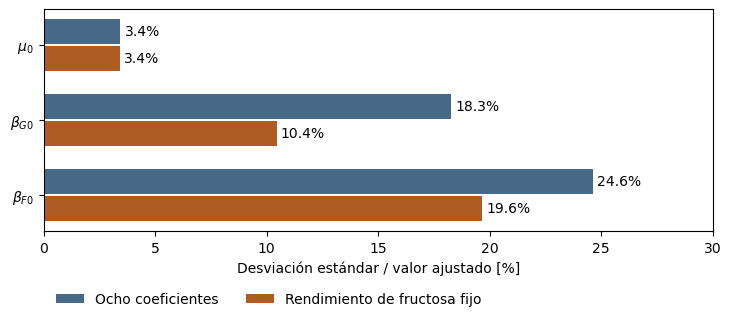

,Varianza con Yef fijo [(1/h)^2]
mu0,0.000010
betaG0,0.001966
betaF0,0.015310


In [4]:
r = residuals.residuo.to_numpy()

def local_covariance(order):
    columns = [names.index(name) for name in order]
    _, singular, vt = np.linalg.svd(J[:, columns], full_matrices=False)
    scaled = vt.T / singular
    nominal = np.array([theta[name] for name in order])
    return ((r @ r) / (len(r) - len(order))) * (scaled @ scaled.T) * np.outer(nominal, nominal)

cov_full = local_covariance(names)
cov_fixed = local_covariance(kept)
np.testing.assert_allclose(cov_full, saved["covarianza_local_fisica"], rtol=1e-10)
np.testing.assert_allclose(cov_fixed, saved["covarianza_local_fisica_Yef_fijo"], rtol=1e-10)

full_variance = np.array([cov_full[names.index(name), names.index(name)] for name in rates])
fixed_variance = np.array([cov_fixed[kept.index(name), kept.index(name)] for name in rates])
np.testing.assert_allclose(np.diag(fixed_variance), saved["D_theta_Yef_fijo"], rtol=1e-10)

nominal = np.array([theta[name] for name in rates])
fig, ax = plt.subplots(figsize=(7.2, 3.1), layout="constrained")
positions = np.arange(len(rates))
for offset, values, label, color in (
    (-.18, full_variance, "Ocho coeficientes", "#466987"),
    (.18, fixed_variance, "Rendimiento de fructosa fijo", "#AE5C24"),
):
    bars = ax.barh(positions + offset, 100 * np.sqrt(values) / nominal, .33, label=label, color=color)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_yticks(positions, [labels[name] for name in rates])
ax.set(xlabel="Desviación estándar / valor ajustado [%]", xlim=(0, 30))
ax.invert_yaxis()
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -.22), ncol=2)
plt.show()
display(pd.DataFrame({"Varianza con Yef fijo [(1/h)^2]": fixed_variance}, index=rates))


Las tres tasas nominales son constantes en el modelo calibrado. Una prueba con perturbaciones por paso representaría una desviación nueva de esas tasas en cada predicción. Una perturbación fija por lote representaría una misma desviación durante toda la fermentación. Las tasas efectivas del modelo ya varían con el estado y la temperatura. Los gráficos describen incertidumbre local del ajuste; la frecuencia de las perturbaciones es un supuesto adicional del filtro.